# Planetary Boundary Transgressions and Divergent Socio-Economic Pathways
### A cross-national quantitative analysis, 1990–2023

**Author:** Sahil · **Institution:** Tata Institute of Social Sciences, Mumbai · **Supervisor:** Dr. Kamal Kumar Murari

This notebook walks through the analysis step by step. The code lives in the `ppi_pathways` package (`src/`), so the notebook, the command-line run (`python -m ppi_pathways`) and the tests all use exactly the same functions.

Analysis version 2.0. See `docs/method-changes.md` for how it differs from the 2026 thesis version (branch `v1.0-thesis`).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path('..', 'src').resolve()))

import pandas as pd
from IPython.display import Image, display
from ppi_pathways import config, data, index, clustering, regression, pipeline

pd.set_option('display.precision', 2)
pd.set_option('display.width', 140)

## 1. Sample

Countries are selected by ISO3 code from the list of 193 UN member states plus the State of Palestine (`data/sovereign_states.csv`), keeping those with a mean population of at least 100,000 over 1990–2023. Matching on codes, not names, keeps regional and income aggregates and dependent territories out of the sample.

In [2]:
panel = data.load_panel()
sample = data.select_sample(panel, data.load_states())
print(f"Raw panel: {panel['iso3'].nunique()} entries, {panel['year'].min()}–{panel['year'].max()}")
print(f"Analytical sample: {sample['iso3'].nunique()} countries, {len(sample):,} country-years")
sample.groupby('period').agg(countries=('iso3', 'nunique'), years=('year', lambda y: f"{y.min()}–{y.max()}"))

Raw panel: 260 entries, 1990–2024
Analytical sample: 182 countries, 6,188 country-years


,countries,years
period,,
D1,182,1990–2000
D2,182,2001–2010
D3,182,2011–2023


## 2. Planetary Pressure Index

Six indicators: renewable energy share and forest cover (both reversed), agricultural land, fertiliser use, PM2.5 exposure and energy use per capita. Each is z-scored over all country-periods together, averaged (at least 4 of 6 required) and rescaled to 0–100 on one common scale, so PPI values can be compared across periods.

In [3]:
periods = index.build_ppi(data.period_means(sample))
periods.groupby('period', observed=True)['ppi'].describe()[['count', 'mean', '50%', 'std', 'min', 'max']]

,count,mean,50%,std,min,max
period,,,,,,
D1,177.0,35.22,36.36,14.60,0.00,100.00
D2,180.0,34.99,35.24,13.29,5.00,84.69
D3,182.0,35.57,36.12,12.92,4.51,82.37


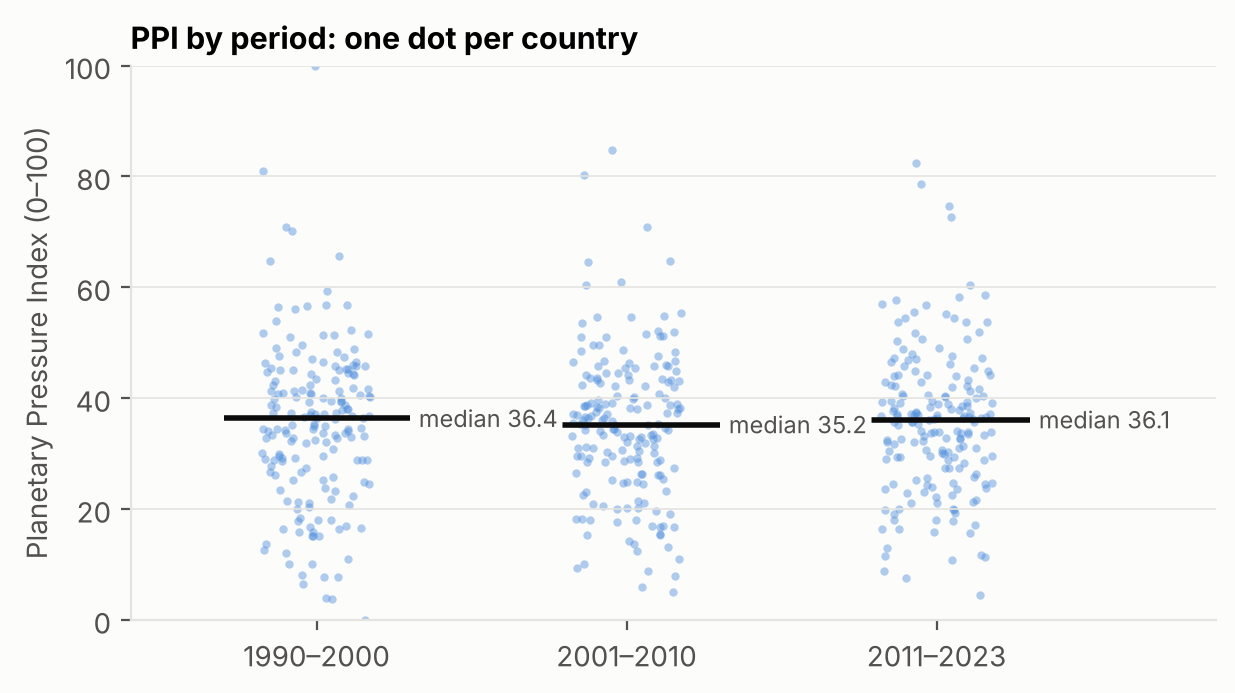

In [4]:
res = pipeline.run()
pipeline.write_outputs(res)
display(Image('../figures/fig2_ppi_by_period.png'))

## 3. Descriptive statistics

In [5]:
res.tables['descriptives'].pivot(index='variable', columns='period', values='mean')

period,1990–2000,2001–2010,2011–2023
variable,,,
Agricultural land (%),39.30,39.08,39.32
Energy use per capita (kgoe),1940.19,2113.87,2342.36
Female labour participation (%),48.80,49.91,50.51
Fertiliser use (kg/ha),169.04,132.63,148.03
Forest cover (%),33.02,32.70,31.93
GDP per capita (US$),5667.46,9796.43,14116.43
"Infant mortality (per 1,000)",46.05,32.42,22.88
Life expectancy (years),64.97,68.19,71.41
PM2.5 exposure (µg/m³),29.60,28.36,27.28


## 4. Pressure–development clusters

One k-means model is fitted to all country-periods together, on standardised PPI, log GDP per capita, life expectancy, infant mortality and urbanisation. Shared centres mean that when a country changes cluster between periods, its indicators actually moved.

Silhouette scores are highest at K = 2. K = 4 is used because it separates development tiers that K = 2 merges; its silhouette (≈ 0.25) indicates overlapping rather than sharply separated groups, so the clusters are best read as a typology, not natural classes.

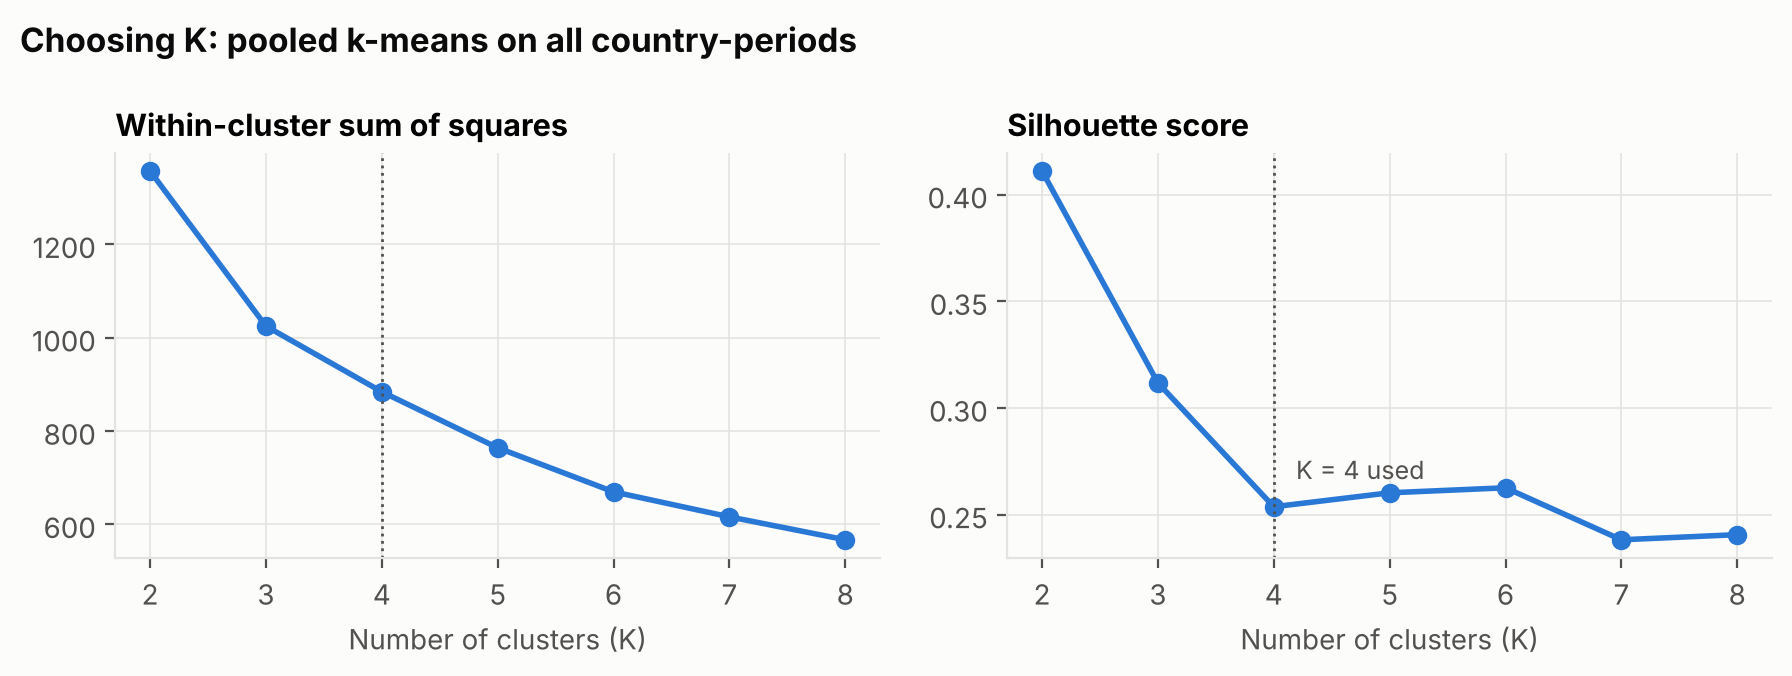

,k,inertia,silhouette
0,2,1357.39,0.41
1,3,1025.03,0.31
2,4,884.30,0.25
3,5,764.29,0.26
4,6,669.89,0.26
5,7,616.29,0.24
6,8,567.11,0.24


In [6]:
display(Image('../figures/fig1_k_diagnostics.png'))
res.k_diag

In [7]:
print(f"Silhouette at K = {config.K}: {res.model.silhouette:.3f}")
res.tables['cluster_centroids']

Silhouette at K = 4: 0.254


,cluster,label,ppi,log_gdp_pc,life_expectancy,infant_mortality,urban_population_pct
0,C1,"Low development, lower pressure",30.37,6.21,53.16,87.20,31.23
1,C2,"Lower-middle development, lower pressure",26.97,7.13,64.77,40.46,36.40
2,C3,"Upper-middle development, higher pressure",36.84,8.29,71.42,19.57,60.45
3,C4,"High development, higher pressure",44.31,10.12,78.28,6.44,80.63


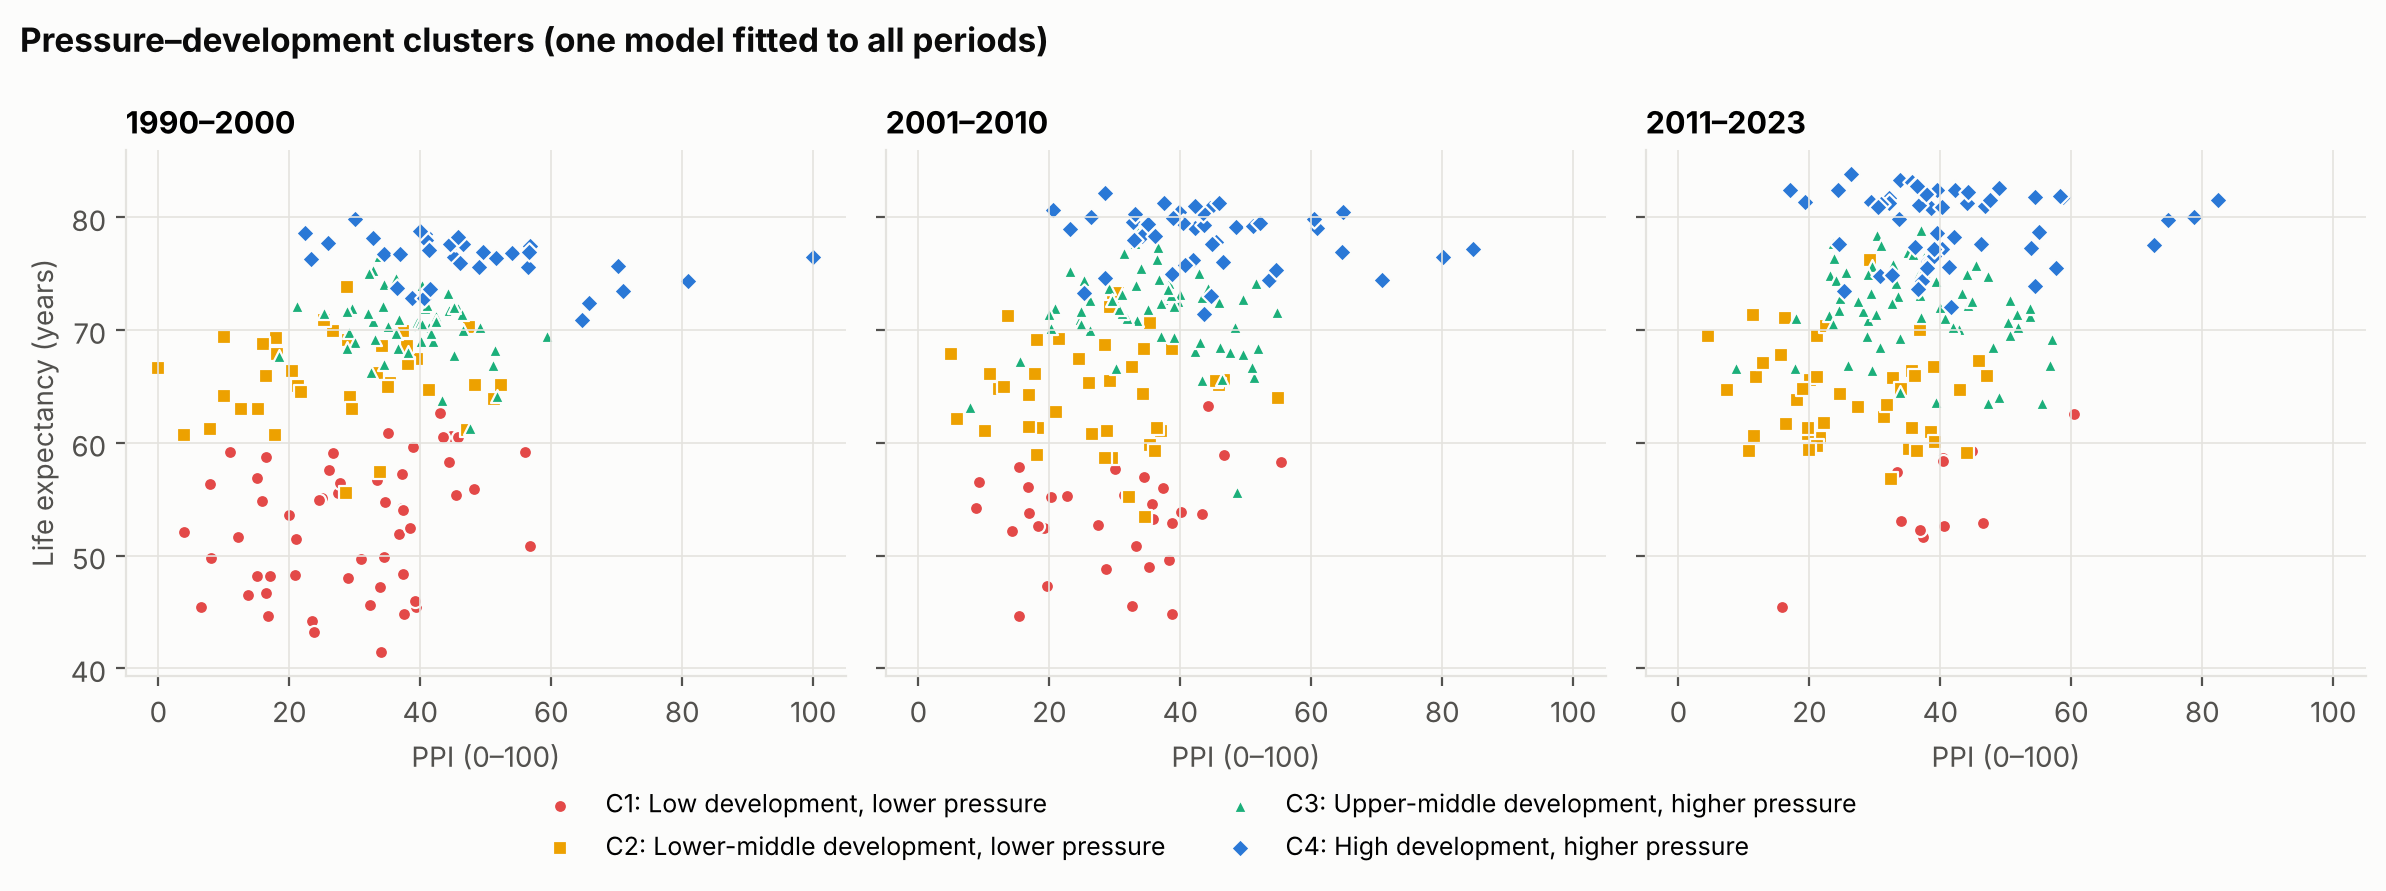

,period,countries,countries_with_ppi,countries_clustered,mean_ppi,median_ppi,n_C1,n_C2,n_C3,n_C4
0,1990–2000,182,177,176,35.22,36.36,53,37,51,35
1,2001–2010,182,180,179,34.99,35.24,32,41,62,44
2,2011–2023,182,182,181,35.57,36.12,11,45,68,57


In [8]:
display(Image('../figures/fig3_clusters_by_period.png'))
res.tables['summary']

## 5. Transitions between periods

1990–2000 → 2001–2010: 72% of countries stayed in the same cluster
2001–2010 → 2011–2023: 70% of countries stayed in the same cluster


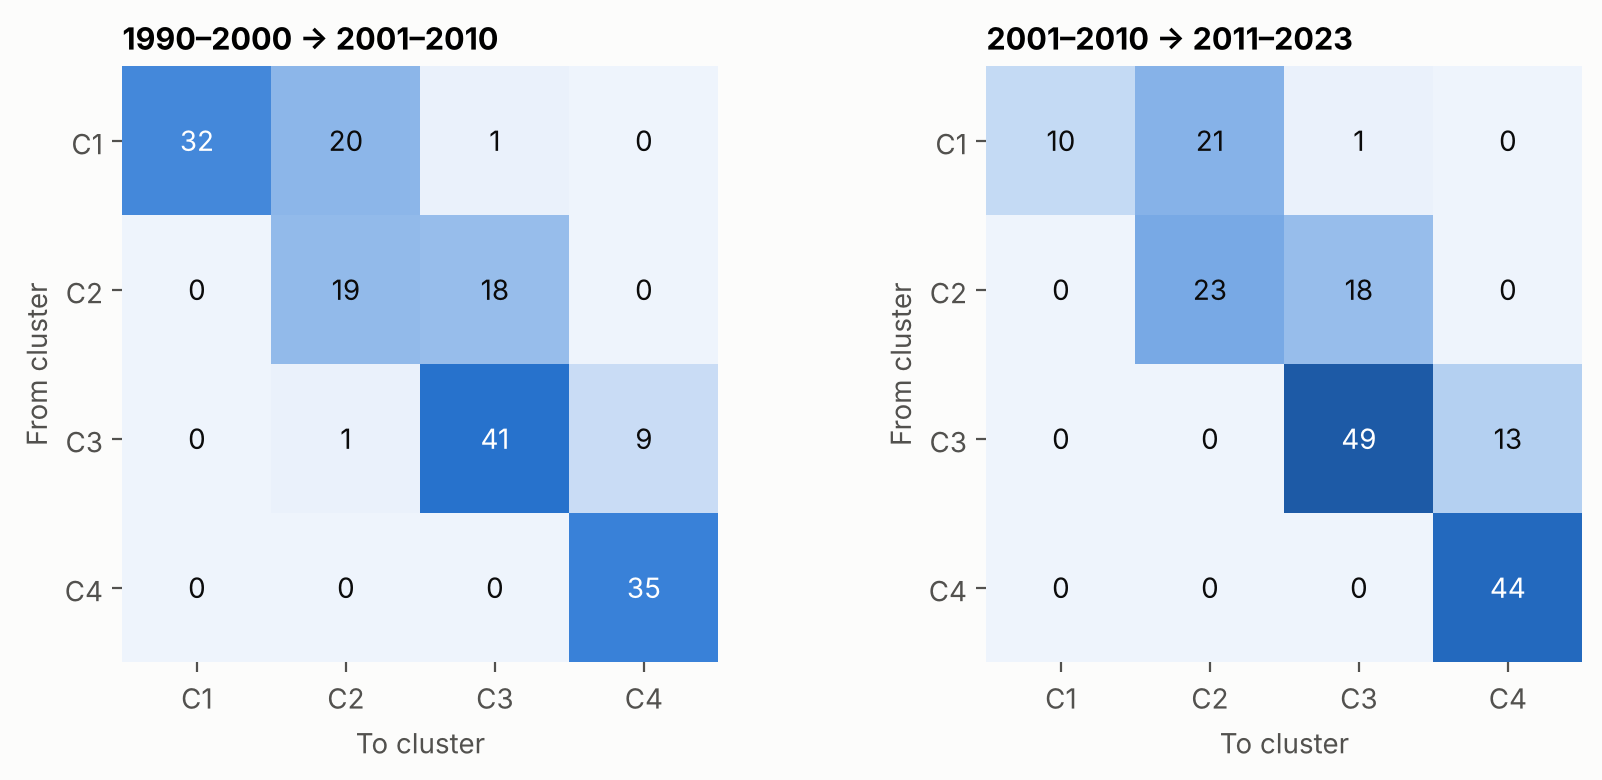

In [9]:
for name, m in res.transitions.items():
    print(f"{name}: {clustering.persistence(m):.0%} of countries stayed in the same cluster")
display(Image('../figures/fig4_transitions.png'))

## 6. Association between the PPI and development outcomes

Bivariate OLS by period. These describe co-variation, not causal effects.

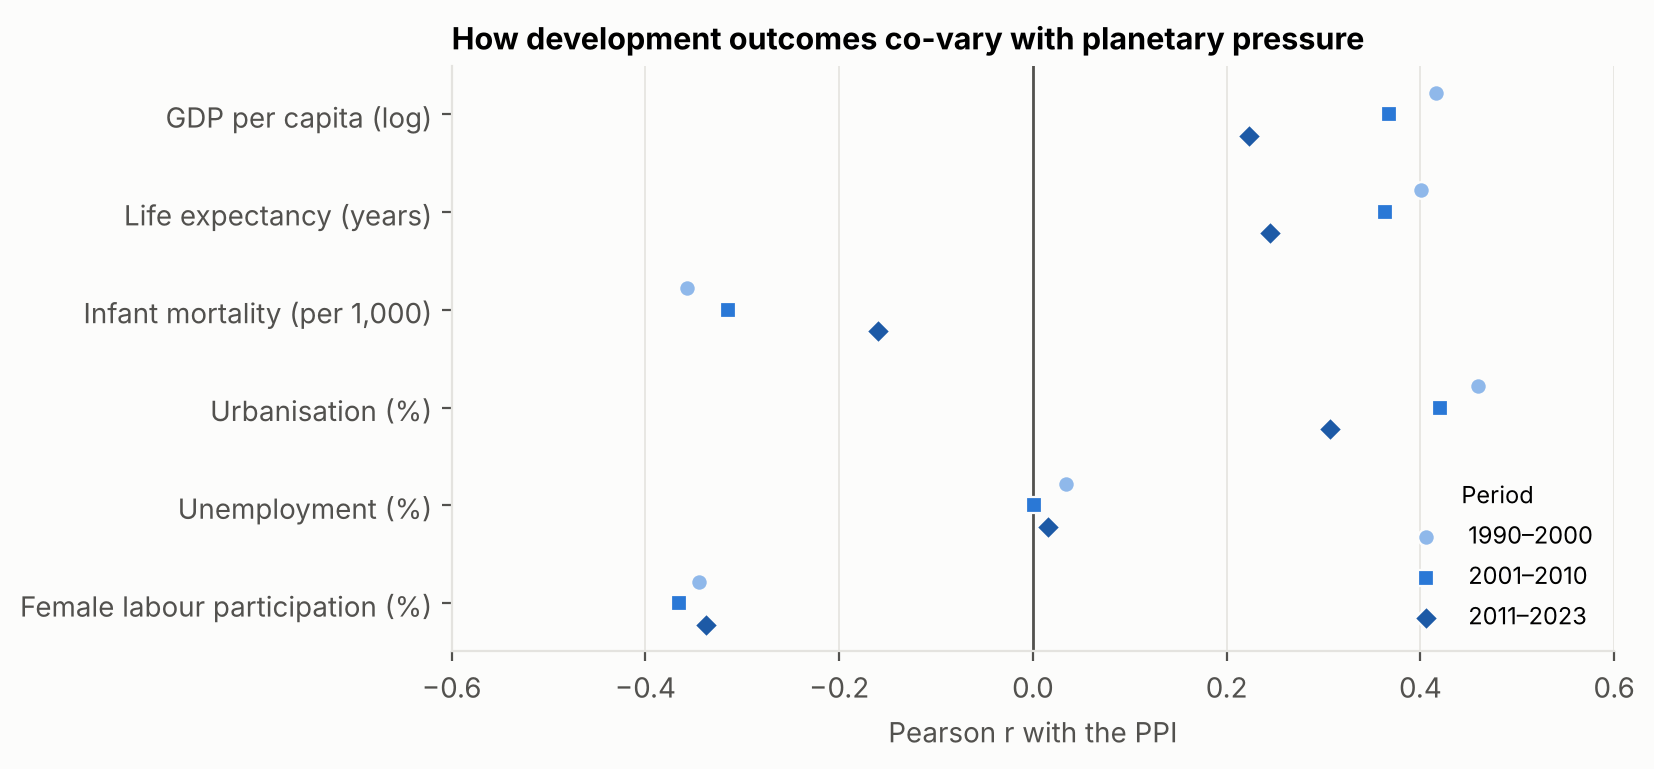

,period,outcome,r,beta,se,p_value,sig,n
0,1990–2000,GDP per capita (log),4.16e-01,4.32e-02,7.16e-03,9.06e-09,***,176
1,1990–2000,Life expectancy (years),4.00e-01,2.67e-01,4.62e-02,3.39e-08,***,177
2,1990–2000,"Infant mortality (per 1,000)",-3.58e-01,-9.11e-01,1.80e-01,1.03e-06,***,177
3,1990–2000,Urbanisation (%),4.59e-01,7.24e-01,1.06e-01,1.29e-10,***,177
4,1990–2000,Unemployment (%),3.40e-02,1.37e-02,3.07e-02,6.56e-01,ns,174
5,1990–2000,Female labour participation (%),-3.45e-01,-4.07e-01,8.45e-02,3.19e-06,***,174
6,2001–2010,GDP per capita (log),3.68e-01,4.20e-02,7.97e-03,4.05e-07,***,179
7,2001–2010,Life expectancy (years),3.63e-01,2.52e-01,4.85e-02,5.41e-07,***,180
8,2001–2010,"Infant mortality (per 1,000)",-3.15e-01,-6.57e-01,1.48e-01,1.66e-05,***,180
9,2001–2010,Urbanisation (%),4.20e-01,7.13e-01,1.15e-01,4.21e-09,***,180


In [10]:
display(Image('../figures/fig5_ppi_correlations.png'))
res.regressions

## 7. Outputs

`python -m ppi_pathways` (or the cell above that calls `pipeline.write_outputs`) writes:
- `results/thesis_results.xlsx` and `results/csv/*.csv`: every table
- `figures/fig1–fig5`
- `docs/data/ppi_animation.json`: data for the interactive chart

## 8. Reproducibility

### Reproducibility
All data, code, and outputs are available at https://github.com/sahiljangra12/Thesis

Dataset sources: World Bank WDI, FAOSTAT, WHO Global Health Observatory, ILO ILOSTAT, UNDP HDR.  
All datasets are open-access. No API keys required.
